# Práctica: _Quantum Phase Estimation_

## Importación de Bibliotecas

In [79]:
from math import pi
from qiskit_aer import AerSimulator
from qiskit import transpile
from qiskit import QuantumCircuit, transpile
from qiskit.visualization import plot_histogram
from qiskit.circuit.library import ZGate, SGate, TGate, RZGate
from qiskit.circuit import Gate
from itertools import product
import pandas as pd
import numpy as np

from collections import Counter, defaultdict

import matplotlib
import matplotlib.pyplot as plt

## Ejercicio 1

### Consigna

Implemente el QPE visto en el curso considerando diferentes operadores unitarios de rotación $U$ y diferentes cantidades de qubits objetivo ($m$) y qubits de estimación ($t$):

i. $U = Z$; $U = S$; $U = T$; $U = Rz(𝝅)$; $U = Rz(𝝅/2)$; $U = Rz(𝝅/4)$; $U = Rz(3𝝅/4)$; ($m = 1$ y $t = 4$).

ii. inciso i) con m = 2

iii. inciso i) con t = 6

iv. U = Rz(-𝝅/4); U = Rz(-3𝝅/4); (m = 1 y t = 4)

### Resolución

#### Transformada Inversa de Fourier

Como paso previo a la implementación del algoritmo QPE, se requiere implementar la transformada inversa cuántica de fourier ($QFT^{-1}$).

Dicha implementación puede extraerse de las resoluciones de los prácticos anteriores.

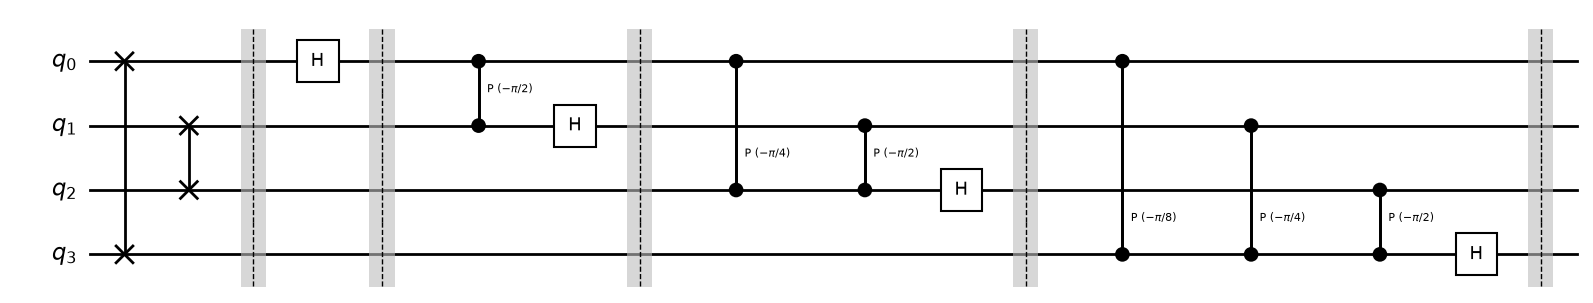

In [80]:
def iqtf(number_of_qubits):
    
    quantum_circuit = QuantumCircuit(number_of_qubits, name="IQTF")
    
    accesible_qubits = number_of_qubits - 1
    
    # Swap entre el qubit 0 y el n - 1.
    # Swap entre el qubit 1 y el n - 2.
    # Y así hasta llegar al centro.
    
    # Los swaps pueden ahorrarse si se invierte el orden de los qubits resultados.
    for i in range(int(number_of_qubits/2)):
        quantum_circuit.swap(i, accesible_qubits - i)
        
    quantum_circuit.barrier()
        
    # Por cada qubit, se aplica una rotación extra.
    # Al primer qubit, solo se le aplica Hadamard.
    # Al segundo, una rotación de pi/2 y Hadamard.
    # Al tercero, una rotación de pi/4, una rotación de pi/2 y Hadamard.
    for i in range(number_of_qubits):
        
        for j in range(i, 0, -1):
            # crz(angulo, control, objetivo)
            quantum_circuit.cp(-pi/(2 ** j), i - j, i)
        
        # Se aplica un Hadamard luego de las rotaciones.
        quantum_circuit.h(i)
        
        # Se aplica una barrera para evitar el autoordenamiento de Qiskit.
        quantum_circuit.barrier()
        
    return quantum_circuit
        
qc = iqtf(4)
qc.draw(output='mpl', style='bw')

#### QPE

A continuación, se define una función que, dado un número de qubits objetivos ($m$), un número de qubits de estimación ($t$) y un ángulo de rotación $\alpha$, devuelve la implementación del QPE correspondiente.

In [81]:
def qpe(qubits_objetivo: int, qubits_estimacion: int, operador_unitario: Gate) -> QuantumCircuit:
    
    qubits_totales: int = qubits_objetivo + qubits_estimacion
    
    quantum_circuit = QuantumCircuit(qubits_totales, name="QPE")
    
    # Se le aplica Hadamard a cada qubit de estimación.
    for i in range(qubits_estimacion):
        quantum_circuit.h(i)
    
    # Operadores unitarios controlados.
    for i in range(qubits_estimacion):
        controlled_u = (operador_unitario ** (2 ** i)).control(1)

        for j in range(qubits_estimacion, qubits_totales):
            quantum_circuit.append(controlled_u, [i, j])
            
    # Aplicación de la transformada cuántica inversa de Fourier.
    quantum_circuit.append(iqtf(qubits_estimacion), range(0, qubits_estimacion))
    
    return quantum_circuit

##### Inciso I)

$m = 1$ y $t = 4$

In [82]:
m = 1
t = 4

Se define una función para obtener los distintos operadores unitarios de rotación $U$ descritos en el enunciado:

In [83]:
def get_unitary_rotation_operator(operator: str) -> Gate:
    operators = {
        "Z": ZGate(),
        "S": SGate(),
        "T": TGate(),
        "Rz(π)": RZGate(pi),
        "Rz(π/2)": RZGate(pi / 2),
        "Rz(π/4)": RZGate(pi / 4),
        "Rz(3π/4)": RZGate(3 * pi / 4),
        "Rz(-π/4)": RZGate(-pi / 4),
        "Rz(-3π/4)": RZGate(-3 * pi / 4),
    }

    if operator not in operators:
        raise ValueError(f"Unsupported operator: {operator}")

    return operators[operator]

In [84]:
def simulate(qc: QuantumCircuit, shots: int = 1024):
    measured_qc = qc.copy()
    measured_qc.measure_all()

    simulator = AerSimulator()
    compiled_qc = transpile(measured_qc, simulator)

    result = simulator.run(compiled_qc, shots=shots).result()

    return result.get_counts()

Se visualiza el circuito para cada uno de los operadores unitarios descritos en el inciso:

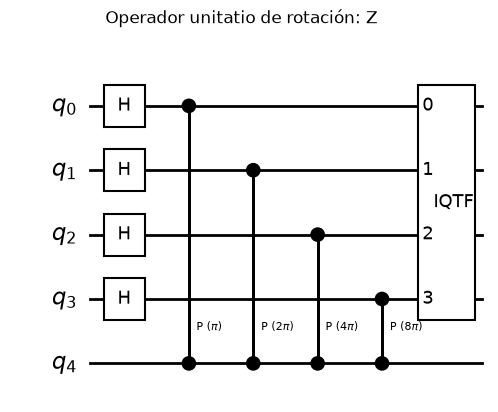

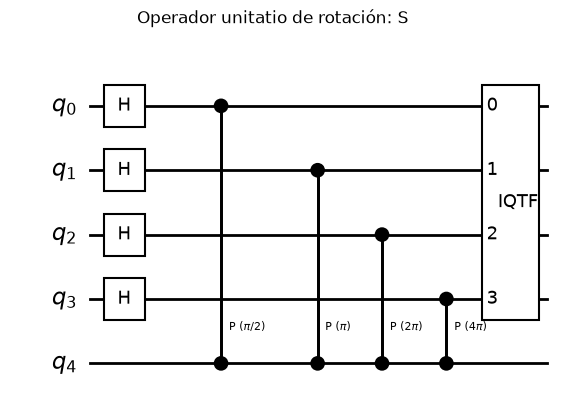

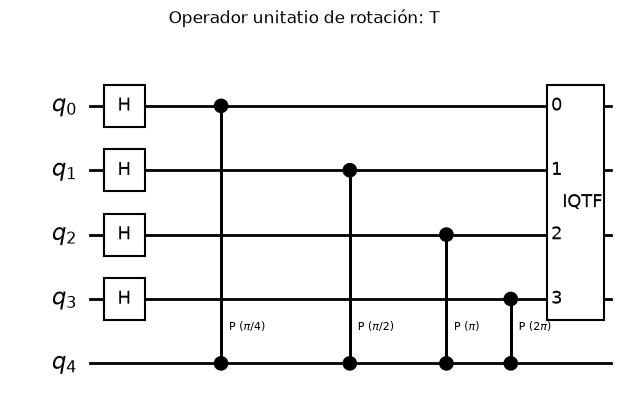

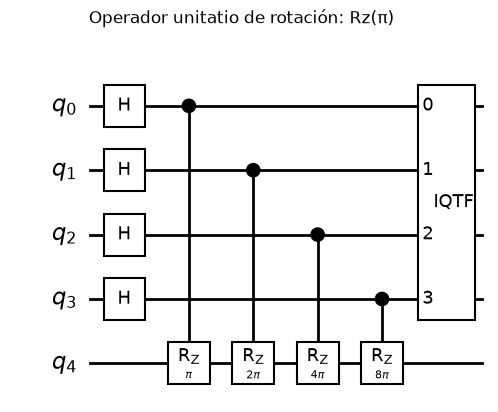

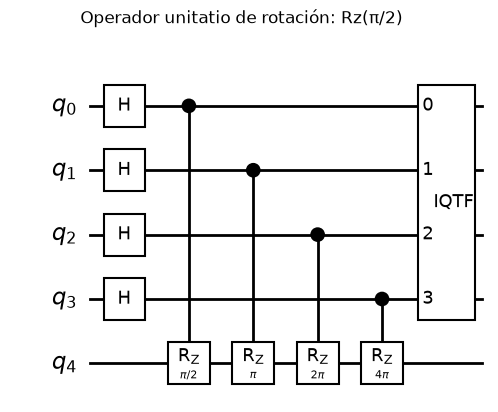

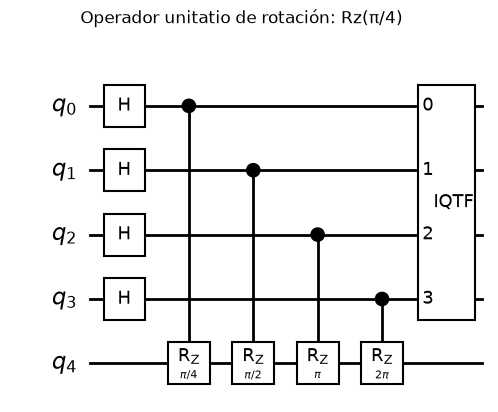

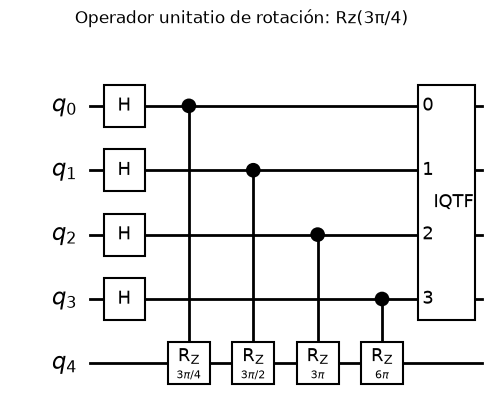

In [85]:
unitary_rotation_operators = ["Z", "S", "T", "Rz(π)", "Rz(π/2)", "Rz(π/4)", "Rz(3π/4)"]

for operator in unitary_rotation_operators:
    qc = qpe(m, t, get_unitary_rotation_operator(operator))

    fig = qc.draw(output="mpl", style="bw")
    fig.suptitle(f"Operador unitatio de rotación: {operator}")
    display(fig)

In [86]:
def build_evaluation_circuit(m: int, t: int, operator: Gate) -> QuantumCircuit:
    # Se obtiene el circuito QPE para dicho operador.
    qpe_qc = qpe(m, t, operator)

    # Se preparan los qubits objetivo en superposición.
    qc = QuantumCircuit(m + t)
    qc.h(range(t, t + m))

    # Se añade el QPE luego de las superposiciones.
    qc.compose(qpe_qc, inplace=True)

    return qc


def group_by_target_state(counts: dict, m: int) -> dict:
    # Se agrupan los resultados por estado objetivo.
    grouped = defaultdict(Counter)

    for measured, occurrences in counts.items():
        bits = measured.replace(" ", "")

        target_state = bits[:m][::-1]
        estimation_bits = bits[m:]

        grouped[target_state][estimation_bits] += occurrences

    return grouped


def expected_phase_of(diagonal: np.ndarray, target_state: str) -> float:
    # Fase teórica: suma de las fases de cada qubit.
    return sum(
        np.angle(diagonal[int(bit)]) / (2 * np.pi)
        for bit in target_state
    ) % 1


def circular_error(measured_phase: float, expected_phase: float) -> float:
    # Error circular entre fases.
    return abs((measured_phase - expected_phase + 0.5) % 1 - 0.5)


def evaluate_operator(operator_name: str, m: int, t: int, shots: int) -> list:
    rows = []

    # Se obtiene el operador unitario.
    operator = get_unitary_rotation_operator(operator_name)
    # Se diagonaliza el operador.
    diagonal = np.diag(operator.to_matrix())

    qc = build_evaluation_circuit(m, t, operator)

    # Se realiza la simulación.
    counts = simulate(qc, shots)
    grouped = group_by_target_state(counts, m)

    max_error = 1 / (2 ** (t + 1)) + 1e-10

    # Se prepara la presentación de los resultados.
    for target_state, outcomes in grouped.items():
        expected_phase = expected_phase_of(diagonal, target_state)

        # Resultado más frecuente.
        measured_bits, measured_occurrences = outcomes.most_common(1)[0]
        measured_phase = int(measured_bits, 2) / (2 ** t)

        # Bits clásicos que se esperarían medir para la fase teórica.
        expected_bits = format(round(expected_phase * 2 ** t) % (2 ** t), f"0{t}b")

        error = circular_error(measured_phase, expected_phase)

        rows.append({
            "Operador": operator_name,
            "Estado objetivo": target_state,
            "Fase esperada": expected_phase,
            "Bits esperados": expected_bits,
            "Fase medida": measured_phase,
            "Bits medidos": measured_bits,
            "Error": error,
            "Ocurrencias": measured_occurrences,
            "Estado": "OK" if error <= max_error else "FALLA"
        })

    return rows


def evaluate_qpe(m: int, t: int, shots: int = 1024, operators: list = unitary_rotation_operators):
    results = []

    # Por cada operador unitario...
    for operator_name in operators:
        results.extend(evaluate_operator(operator_name, m, t, shots))

    return pd.DataFrame(results)

In [87]:
# Se establecen los parámetros.
m = 1
t = 4

# Se evalúa el circuito.
display(evaluate_qpe(m, t))

,Operador,Estado objetivo,Fase esperada,Bits esperados,Fase medida,Bits medidos,Error,Ocurrencias,Estado
0,Z,1,0.5000,1000,0.5000,1000,0.0,520,OK
1,Z,0,0.0000,0000,0.0000,0000,0.0,504,OK
2,S,0,0.0000,0000,0.0000,0000,0.0,496,OK
3,S,1,0.2500,0100,0.2500,0100,0.0,528,OK
4,T,0,0.0000,0000,0.0000,0000,0.0,498,OK
5,T,1,0.1250,0010,0.1250,0010,0.0,526,OK
6,Rz(π),0,0.7500,1100,0.7500,1100,0.0,481,OK
7,Rz(π),1,0.2500,0100,0.2500,0100,0.0,543,OK
8,Rz(π/2),0,0.8750,1110,0.8750,1110,0.0,507,OK
9,Rz(π/2),1,0.1250,0010,0.1250,0010,0.0,517,OK


#### Inciso ii)

Mismas instrucciones que para el inciso i), pero utilizando $m = 2$ en lugar de $m = 1$.

In [88]:
# Se establecen los parámetros.
m = 2
t = 4

# Se evalúa el circuito.
display(evaluate_qpe(m, t))

,Operador,Estado objetivo,Fase esperada,Bits esperados,Fase medida,Bits medidos,Error,Ocurrencias,Estado
0,Z,00,0.000,0000,0.000,0000,0.0,250,OK
1,Z,01,0.500,1000,0.500,1000,0.0,256,OK
2,Z,10,0.500,1000,0.500,1000,0.0,251,OK
3,Z,11,0.000,0000,0.000,0000,0.0,267,OK
4,S,11,0.500,1000,0.500,1000,0.0,269,OK
5,S,01,0.250,0100,0.250,0100,0.0,241,OK
6,S,00,0.000,0000,0.000,0000,0.0,238,OK
7,S,10,0.250,0100,0.250,0100,0.0,276,OK
8,T,10,0.125,0010,0.125,0010,0.0,249,OK
9,T,11,0.250,0100,0.250,0100,0.0,255,OK


#### Inciso iii)

Mismas instrucciones que para el inciso i), pero modificando el valor de $t$ de $t = 4$ a $t = 6$.

In [89]:
# Se establecen los parámetros.
m = 1
t = 6

# Se evalúa el circuito.
display(evaluate_qpe(m, t))

,Operador,Estado objetivo,Fase esperada,Bits esperados,Fase medida,Bits medidos,Error,Ocurrencias,Estado
0,Z,1,0.5000,100000,0.5000,100000,0.0,515,OK
1,Z,0,0.0000,000000,0.0000,000000,0.0,509,OK
2,S,0,0.0000,000000,0.0000,000000,0.0,512,OK
3,S,1,0.2500,010000,0.2500,010000,0.0,512,OK
4,T,1,0.1250,001000,0.1250,001000,0.0,487,OK
5,T,0,0.0000,000000,0.0000,000000,0.0,537,OK
6,Rz(π),1,0.2500,010000,0.2500,010000,0.0,514,OK
7,Rz(π),0,0.7500,110000,0.7500,110000,0.0,510,OK
8,Rz(π/2),0,0.8750,111000,0.8750,111000,0.0,506,OK
9,Rz(π/2),1,0.1250,001000,0.1250,001000,0.0,518,OK


No se observa ninguna modificación en los vvalores. Añadir 2 bits más de estimación no mejoró la precisión el resultado. Como puede observarse en la tabla, los últimos dos bits se encuentran en 0 en todos los resultados. No realizan ningún aporte.

#### Inciso iv)

El inciso pide, utilizando $m = 1$ y $t = 4$, probar la implementación para un nuevo conjunto de operadores unitarios:

- $U = Rz(-𝝅/4)$; y
- $U = Rz(-3𝝅/4)$.

In [90]:
# Se establecen los valores de los parámetros.
m = 1
t = 4

# Se definen los nuevos operadores untiarios a utilizar.
unitary_rotation_operators_iv = ["Rz(-π/4)", "Rz(-3π/4)"]

# Se evaluá el circuito.
display(evaluate_qpe(m, t, operators=unitary_rotation_operators_iv))

,Operador,Estado objetivo,Fase esperada,Bits esperados,Fase medida,Bits medidos,Error,Ocurrencias,Estado
0,Rz(-π/4),1,0.9375,1111,0.9375,1111,0.0,477,OK
1,Rz(-π/4),0,0.0625,0001,0.0625,0001,0.0,547,OK
2,Rz(-3π/4),1,0.8125,1101,0.8125,1101,0.0,485,OK
3,Rz(-3π/4),0,0.1875,0011,0.1875,0011,0.0,539,OK


## Ejercicio 2

### Consigna

Analice para el ejercicio 1.i) el impacto de la fase global en los autovalores

### Resolución

Para observar el impacto de la fase global en los autovalores, se evalua el circuito con los operadores unitarios de rotación $Z$ y $Rz(\pi)$.

In [91]:
# Se establecen los valores de los parámetros.
m = 1
t = 4

# Se definen los nuevos operadores untiarios a utilizar.
unitary_rotation_operators_2 = ["Z", "Rz(π)"]

# Se evaluá el circuito.
display(evaluate_qpe(m, t, operators=unitary_rotation_operators_2))

,Operador,Estado objetivo,Fase esperada,Bits esperados,Fase medida,Bits medidos,Error,Ocurrencias,Estado
0,Z,1,0.50,1000,0.50,1000,0.0,504,OK
1,Z,0,0.00,0000,0.00,0000,0.0,520,OK
2,Rz(π),0,0.75,1100,0.75,1100,0.0,520,OK
3,Rz(π),1,0.25,0100,0.25,0100,0.0,504,OK


Ambos operadores de rotación realizan una rotación $\pi$ sobre el eje Z. No obstante, $Rz(\pi)$ difiere de $Z$ en una fase global:

$$
Rz(\pi) = \begin{pmatrix} e^{-i\pi/2} & 0 \\ 0 & e^{i\pi/2} \end{pmatrix} = \begin{pmatrix} -i & 0 \\ 0 & i \end{pmatrix} = -i\,Z
$$

Si estas compuertas se aplicaran a un qubit y se realizara la medición, las probabilidades observadas serían las mismas para cualquier estado, ya que una fase global no es observable. Sin embargo, como se observa en la tabla anterior, esto no se cumple en el circuito QPE.

Los autovalores de $Z$ son $1$ y $-1$, mientras que los de $Rz(\pi)$ son $-i$ y $i$. Es decir, la fase global $e^{-i\pi/2}$ multiplica ambos autovalores, lo que desplaza las dos fases estimadas en $-0.25$ (módulo 1). La diferencia entre las fases de $\lvert 0 \rangle$ y $\lvert 1 \rangle$ se mantiene en $0.5$.

Esto ocurre porque el QPE utiliza el operador controlado. Cuando el qubit de control está en $\lvert 1 \rangle$, se aplica $U$ al objetivo, y cuando está en $\lvert 0 \rangle$, no se aplica nada. Por lo tanto, la fase global de $U$ deja de ser global y pasa a ser una fase relativa entre $\lvert 0 \rangle$ y $\lvert 1 \rangle$ del qubit de control (_phase kickback_), que es justamente lo que el QPE estima.

En conclusión, la fase global no afecta las probabilidades de medición de un estado, pero sí la fase estimada por el QPE, por lo que el operador debe especificarse con su fase global incluida.